# MACHINE LEARNING SAML-D

In [3]:
import pandas as pd 
import numpy as np 
import matplotlib as mtl 
import seaborn as sns 
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [4]:
dataset = pd.read_csv('SAML-D.csv')

# Pré-processamento
- Preparar as variáveis numéricas e categóricas
- Escalonamento
- Investigar desbalanceamento
- Engenharia de atributos
- Pipeline

### Combinando Data e Horário

In [18]:
print(dataset[["Date", "Time"]].head())
print(dataset[["Date", "Time"]].dtypes)

# Converte a data para datetime
dataset["Date"] = pd.to_datetime(
    dataset["Date"],
    errors="coerce"
)

data_texto = dataset["Date"].dt.strftime("%Y-%m-%d")

horario_texto = dataset["Time"].astype("string").str.strip()

dataset["Timestamp"] = pd.to_datetime(
    data_texto + " " + horario_texto,
    errors="coerce"
)
print("Timestamps inválidos:", dataset["Timestamp"].isna().sum())
display(dataset[["Date", "Time", "Timestamp"]].head(10))

         Date      Time
0  2022-10-07  10:35:19
1  2022-10-07  10:35:20
2  2022-10-07  10:35:20
3  2022-10-07  10:35:21
4  2022-10-07  10:35:21
Date    str
Time    str
dtype: object
Timestamps inválidos: 0


,Date,Time,Timestamp
0,2022-10-07,10:35:19,2022-10-07 10:35:19
1,2022-10-07,10:35:20,2022-10-07 10:35:20
2,2022-10-07,10:35:20,2022-10-07 10:35:20
3,2022-10-07,10:35:21,2022-10-07 10:35:21
4,2022-10-07,10:35:21,2022-10-07 10:35:21
5,2022-10-07,10:35:21,2022-10-07 10:35:21
6,2022-10-07,10:35:23,2022-10-07 10:35:23
7,2022-10-07,10:35:23,2022-10-07 10:35:23
8,2022-10-07,10:35:26,2022-10-07 10:35:26
9,2022-10-07,10:35:29,2022-10-07 10:35:29


### Ordem das Transações

In [19]:
dataset = dataset.sort_values("Timestamp").reset_index(drop=True)

display(dataset[["Timestamp", "Sender_account", "Receiver_account", "Amount"]].head(10))


,Timestamp,Sender_account,Receiver_account,Amount
0,2022-10-07 10:35:19,8724731955,2769355426,1459.15
1,2022-10-07 10:35:20,1491989064,8401255335,6019.64
2,2022-10-07 10:35:20,287305149,4404767002,14328.44
3,2022-10-07 10:35:21,5376652437,9600420220,11895.00
4,2022-10-07 10:35:21,9614186178,3803336972,115.25
5,2022-10-07 10:35:21,8974559268,3143547511,5130.99
6,2022-10-07 10:35:23,980191499,8577635959,12176.52
7,2022-10-07 10:35:23,8057793308,9350896213,56.90
8,2022-10-07 10:35:26,6116657264,656192169,4738.45
9,2022-10-07 10:35:29,7421451752,2755709071,5883.87


### Características Temporais: Hora do Dia, Dia da Semana e do Mês

In [20]:
# Hora do dia: valores de 0 a 23
dataset["hora_dia"] = dataset["Timestamp"].dt.hour

# Dia da semana: segunda = 0, domingo = 6
dataset["dia_semana"] = dataset["Timestamp"].dt.dayofweek

# Dia do mês: valores de 1 a 31
dataset["dia_mes"] = dataset["Timestamp"].dt.day

display(
    dataset[["Timestamp", "hora_dia", "dia_semana", "dia_mes"]].head(10)
)

display(
    dataset[["Timestamp", "hora_dia", "dia_semana", "dia_mes"]].tail(10)
)



,Timestamp,hora_dia,dia_semana,dia_mes
0,2022-10-07 10:35:19,10,4,7
1,2022-10-07 10:35:20,10,4,7
2,2022-10-07 10:35:20,10,4,7
3,2022-10-07 10:35:21,10,4,7
4,2022-10-07 10:35:21,10,4,7
5,2022-10-07 10:35:21,10,4,7
6,2022-10-07 10:35:23,10,4,7
7,2022-10-07 10:35:23,10,4,7
8,2022-10-07 10:35:26,10,4,7
9,2022-10-07 10:35:29,10,4,7


,Timestamp,hora_dia,dia_semana,dia_mes
9504842,2023-08-23 10:56:44,10,2,23
9504843,2023-08-23 10:56:45,10,2,23
9504844,2023-08-23 10:56:52,10,2,23
9504845,2023-08-23 10:56:54,10,2,23
9504846,2023-08-23 10:56:56,10,2,23
9504847,2023-08-23 10:57:01,10,2,23
9504848,2023-08-23 10:57:06,10,2,23
9504849,2023-08-23 10:57:06,10,2,23
9504850,2023-08-23 10:57:11,10,2,23
9504851,2023-08-23 10:57:12,10,2,23


In [21]:
print(dataset[["hora_dia", "dia_semana", "dia_mes"]].nunique())

hora_dia      24
dia_semana     7
dia_mes       31
dtype: int64


### Quantidade de Transações por Horário

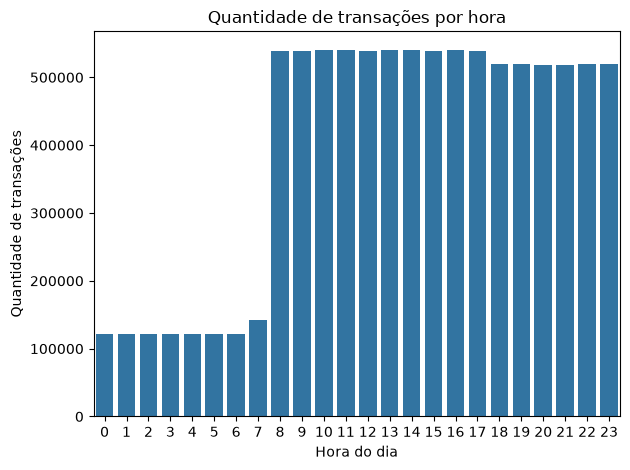

In [22]:
sns.countplot(data=dataset, x="hora_dia")
plt.title("Quantidade de transações por hora")
plt.xlabel("Hora do dia")
plt.ylabel("Quantidade de transações")
plt.tight_layout()
plt.show()


### Transações Positivas por Horário

In [23]:
taxa_por_hora = (
    dataset.groupby("hora_dia")["Is_laundering"]
    .agg(["count", "sum", "mean"])
)

taxa_por_hora["taxa_percentual"] = taxa_por_hora["mean"] * 100

display(taxa_por_hora)


,count,sum,mean,taxa_percentual
hora_dia,,,,
0,121548,136,0.001119,0.111890
1,121964,122,0.001000,0.100030
2,121627,138,0.001135,0.113462
3,121282,138,0.001138,0.113784
4,121568,126,0.001036,0.103646
5,122114,140,0.001146,0.114647
6,121484,146,0.001202,0.120180
7,142497,222,0.001558,0.155793
8,538992,632,0.001173,0.117256


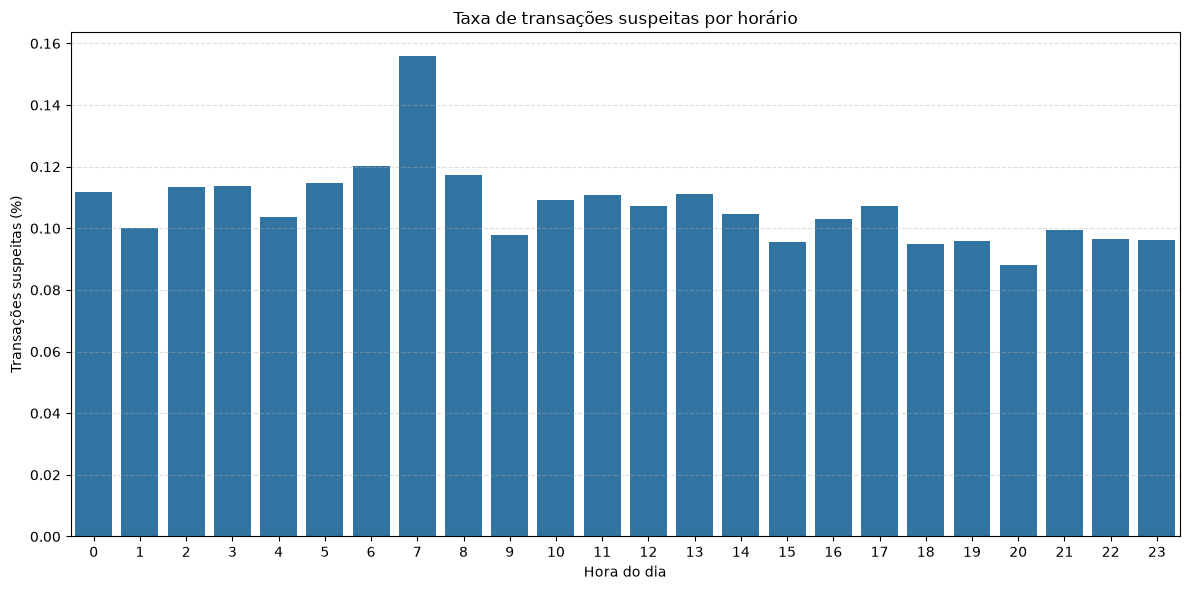

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=taxa_por_hora.reset_index(),
    x="hora_dia",
    y="taxa_percentual"
)

plt.title("Taxa de transações suspeitas por horário")
plt.xlabel("Hora do dia")
plt.ylabel("Transações suspeitas (%)")

plt.xticks(range(24))
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### Operações entre Países Diferentes

In [41]:
dataset["operacao_internacional"] = (
    dataset["Sender_bank_location"]
    != dataset["Receiver_bank_location"]
).astype("int8")

display(
    dataset[
        [
            "Sender_bank_location",
            "Receiver_bank_location",
            "operacao_internacional"
        ]
    ].head(15)
)

display(
    dataset[
        [
            "Sender_bank_location",
            "Receiver_bank_location",
            "operacao_internacional"
        ]
    ].tail(15)
)

,Sender_bank_location,Receiver_bank_location,operacao_internacional
0,UK,UK,0
1,UK,UAE,1
2,UK,UK,0
3,UK,UK,0
4,UK,UK,0
5,UK,UK,0
6,UK,UK,0
7,UK,UK,0
8,UK,UK,0
9,UK,UK,0


,Sender_bank_location,Receiver_bank_location,operacao_internacional
9504837,UK,UK,0
9504838,UK,India,1
9504839,UK,UK,0
9504840,UK,UK,0
9504841,UK,UK,0
9504842,UK,UK,0
9504843,UK,UK,0
9504844,UK,UK,0
9504845,UK,UK,0
9504846,UK,UK,0


In [42]:
# Cria o encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

categorias = dataset[["Payment_type"]].head(10)

# Transforma as linhas em indicadores
resultado = encoder.fit_transform(categorias)

colunas_geradas = encoder.get_feature_names_out(["Payment_type"])

# Converte o resultado em um Dataframe para visualização
df_codificado = pd.DataFrame(
    resultado,
    columns=colunas_geradas,
    index=categorias.index
)

display(df_codificado)

,Payment_type_ACH,Payment_type_Cash Deposit,Payment_type_Cheque,Payment_type_Credit card,Payment_type_Cross-border
0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,1.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0
5,1.0,0.0,0.0,0.0,0.0
6,1.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,1.0,0.0
8,0.0,0.0,1.0,0.0,0.0
9,0.0,0.0,0.0,1.0,0.0


### Definição de Características

In [43]:
colunas_numericas = [
    "Amount",
    "hora_dia",
    "dia_semana",
    "dia_mes",
    "operacao_internacional"
]

colunas_categoricas = [
    "Payment_type",
    "Payment_currency",
    "Received_currency",
    "Sender_bank_location",
    "Receiver_bank_location"
]

colunas_features = colunas_numericas + colunas_categoricas

# Dados de treinamento
X = dataset[colunas_features].copy()
# Dados de predição
y = dataset["Is_laundering"].copy()

print("\nDimensões das características X:", X.shape)
print("Dimensões do alvo y:", y.shape)

print("\nTipos de X:")
print(X.dtypes)


Dimensões das características X: (9504852, 10)
Dimensões do alvo y: (9504852,)

Tipos de X:
Amount                    float64
hora_dia                    int32
dia_semana                  int32
dia_mes                     int32
operacao_internacional       int8
Payment_type                  str
Payment_currency              str
Received_currency             str
Sender_bank_location          str
Receiver_bank_location        str
dtype: object


### Transformações Numéricas e Escalonamento

In [44]:
# Escalonamento: Pipeline Numérico
transformador_numerico = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

# Escalonamento: Pipeline Categórico
transformador_categorico = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Pré-Processamento: Numéricos e Categóricos
preprocessador = ColumnTransformer(transformers=[
    ("num", transformador_numerico, colunas_numericas),
    ("cat", transformador_categorico, colunas_categoricas)
])

### Teste do Pré-Processamento
Aplica as transformação a uma pequena amostra para inspecionar o resultado.

In [45]:
amostra = X.head(1000).copy()

amostra_processada = preprocessador.fit_transform(amostra)

print("\nDimensões antes do pré-processamento:", amostra.shape)
print("Dimensões depois do pré-processamento:", amostra_processada.shape)

# Exibe os nomes das características resultantes.
# O OneHotEncoder pode criar muitas colunas, portanto mostramos
# apenas os primeiros nomes.

nomes_caracteristicas = preprocessador.get_feature_names_out()

print("\nPrimeiras características após a transformação:")
print(nomes_caracteristicas[:30])

# Converte uma pequena parte do resultado em DataFrame para
# facilitar a visualização. Não convertemos o dataset inteiro
# para uma matriz densa, pois isso pode consumir muita memória.

amostra_densa = (
    amostra_processada[:10].toarray()
    if hasattr(amostra_processada, "toarray")
    else amostra_processada[:10]
)

df_processado = pd.DataFrame(
    amostra_densa,
    columns=nomes_caracteristicas
)

display(df_processado)


Dimensões antes do pré-processamento: (1000, 10)
Dimensões depois do pré-processamento: (1000, 65)

Primeiras características após a transformação:
['num__Amount' 'num__hora_dia' 'num__dia_semana' 'num__dia_mes'
 'num__operacao_internacional' 'cat__Payment_type_ACH'
 'cat__Payment_type_Cash Deposit' 'cat__Payment_type_Cash Withdrawal'
 'cat__Payment_type_Cheque' 'cat__Payment_type_Credit card'
 'cat__Payment_type_Cross-border' 'cat__Payment_type_Debit card'
 'cat__Payment_currency_Albanian lek' 'cat__Payment_currency_Dirham'
 'cat__Payment_currency_Euro' 'cat__Payment_currency_Indian rupee'
 'cat__Payment_currency_Mexican Peso' 'cat__Payment_currency_Naira'
 'cat__Payment_currency_Pakistani rupee'
 'cat__Payment_currency_Swiss franc' 'cat__Payment_currency_UK pounds'
 'cat__Payment_currency_Yen' 'cat__Received_currency_Albanian lek'
 'cat__Received_currency_Dirham' 'cat__Received_currency_Euro'
 'cat__Received_currency_Indian rupee'
 'cat__Received_currency_Mexican Peso'
 'cat__Receiv

,num__Amount,num__hora_dia,num__dia_semana,num__dia_mes,num__operacao_internacional,cat__Payment_type_ACH,cat__Payment_type_Cash Deposit,cat__Payment_type_Cash Withdrawal,cat__Payment_type_Cheque,cat__Payment_type_Credit card,...,cat__Receiver_bank_location_Morocco,cat__Receiver_bank_location_Netherlands,cat__Receiver_bank_location_Nigeria,cat__Receiver_bank_location_Pakistan,cat__Receiver_bank_location_Spain,cat__Receiver_bank_location_Switzerland,cat__Receiver_bank_location_Turkey,cat__Receiver_bank_location_UAE,cat__Receiver_bank_location_UK,cat__Receiver_bank_location_USA
0,-0.819450,-0.732187,0.0,0.0,-0.318311,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.164416,-0.732187,0.0,0.0,3.141586,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,1.028996,-0.732187,0.0,0.0,-0.318311,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.679476,-0.732187,0.0,0.0,-0.318311,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-1.012477,-0.732187,0.0,0.0,-0.318311,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5,-0.292055,-0.732187,0.0,0.0,-0.318311,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6,0.719911,-0.732187,0.0,0.0,-0.318311,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7,-1.020858,-0.732187,0.0,0.0,-0.318311,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
8,-0.348436,-0.732187,0.0,0.0,-0.318311,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
9,-0.183917,-0.732187,0.0,0.0,-0.318311,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [46]:
display(
    dataset[
        [
            "Amount",
            "Date",
            "Time",
            "Payment_type",
            "Sender_bank_location",
            "Receiver_bank_location",
            "Is_laundering"
        ]
    ].head(10)
)

,Amount,Date,Time,Payment_type,Sender_bank_location,Receiver_bank_location,Is_laundering
0,1459.15,2022-10-07,10:35:19,Cash Deposit,UK,UK,0
1,6019.64,2022-10-07,10:35:20,Cross-border,UK,UAE,0
2,14328.44,2022-10-07,10:35:20,Cheque,UK,UK,0
3,11895.00,2022-10-07,10:35:21,ACH,UK,UK,0
4,115.25,2022-10-07,10:35:21,Cash Deposit,UK,UK,0
5,5130.99,2022-10-07,10:35:21,ACH,UK,UK,0
6,12176.52,2022-10-07,10:35:23,ACH,UK,UK,0
7,56.90,2022-10-07,10:35:23,Credit card,UK,UK,0
8,4738.45,2022-10-07,10:35:26,Cheque,UK,UK,0
9,5883.87,2022-10-07,10:35:29,Credit card,UK,UK,0


In [47]:
display(
    dataset[
        ["hora_dia", "dia_semana", "dia_mes"]
    ].nunique()
)

hora_dia      24
dia_semana     7
dia_mes       31
dtype: int64